<a href="https://colab.research.google.com/github/HuriyaAhmerr/AIP/blob/main/AIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universal Plus – E-Mail Marketing Targeting
**IB9BW0 Analytics in Practice**

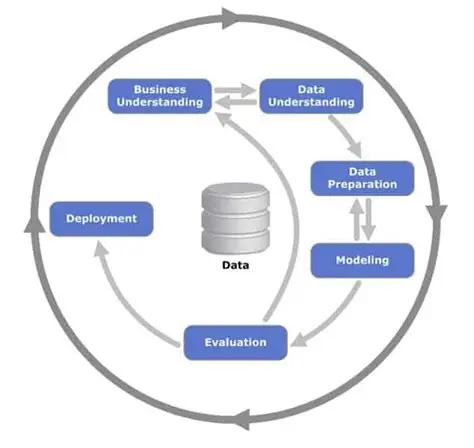





## 1. Business Understanding

**Business figures from the board:**
- Cost per e-mail: £3.50
- Value of a visit: £93 average spend × 30% margin ≈ £28


**Business problem:** Today, decisions about who receives a campaign e-mail are mostly made by rules of thumb or at random. Targeting uninterested customers costs money, and several past campaigns were not successful.

The company wants a system that predicts whether each customer will visit the shop after a campaign.


## 2. Data Understanding


### The Datasets
| File | Rows | Columns | Contains `visit`? |
|---|---|---|---|
| `campaign_data.csv` | 52,000 | 21 | Yes |
| `next_campaign.csv` | 12,000 | 20 | No |

**campaign_data.csv** – contains the 52,000 customers who took part in the test campaign. For each
customer it records 21 attributes, including the e-mail they received and whether they visited the shop.  

**next_campaign.csv** – contains 12,000 further customers from the same campaign. It holds the same
information as the first file, except that it does not say whether these customers visited the shop. Universal
Plus has shared this file to see how your system would be used in its next campaign


In [1]:
print(open("readme.txt").read())

1. Title: E-Mail Marketing

Universal Plus randomly sent an e-mail marketing campaign to some of its customers.
Some customers received a campaign on women's products, some received a campaign on men's products,
and some did not receive an e-mail campaign at all.
The company collected data for all of these customers (including the ones who did not receive the campaign)
during the two weeks following the e-mail campaign.

2. Files and number of instances

   campaign_data.csv            52,000 customers, all 21 attributes listed below.
   next_campaign.csv		12,000 further customers from the same campaign. All attributes 				are provided except `visit`, which has been withheld. Universal 				Plus has shared this file to see how your system would be used 					in its next campaign.

3. Number of attributes: 21

4. Attribute information:

  1) Customer_ID: Customer identification number
  2) recency: Months since last purchase before the marketing campaign
  3) purchase_segment: Categorisat

-----
### 2.1 Load the data and take a first look

In [4]:
# Import the libraries
import pandas as pd
import numpy as np

# Load the files.
df = pd.read_csv("campaign_data.csv")
nxt = pd.read_csv("next_campaign.csv")

# How many rows and columns?
print(df.shape)
print(nxt.shape)

(52000, 21)
(12000, 20)


In [5]:
# The first five rows
df.head()

,Customer_ID,recency,purchase_segment,purchase,mens,womens,zip_area,new_customer,channel,email_segment,...,dependent,account,employed,phone,delivery,marriage,payment_card,satisfaction_score,spend,visit
0,30000001,12.0,1) 0 - 100,81.61,1,0,Urban,0,Phone,No E-Mail,...,1,1,1,1,1,0,1,NaN,0.0,0
1,30000004,NaN,3) 200 - 350,258.74,1,0,Urban,0,Multichannel,Mens E-Mail,...,1,1,1,1,3,0,1,8.0,0.0,0
2,30000005,6.0,3) 200 - 350,239.96,1,0,Suburban,0,Phone,No E-Mail,...,0,1,1,1,1,1,1,NaN,0.0,0
3,30000006,7.0,3) 200 - 350,268.18,1,1,Rural,1,Web,Womens E-Mail,...,1,1,1,1,3,2,0,5.0,0.0,0
4,30000007,1.0,3) 200 - 350,311.52,0,1,Suburban,0,Web,No E-Mail,...,0,1,1,1,3,1,1,8.0,0.0,0


In [6]:
# The structure: column names, data types and the number of non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         52000 non-null  int64  
 1   recency             48238 non-null  float64
 2   purchase_segment    51977 non-null  object 
 3   purchase            52000 non-null  float64
 4   mens                52000 non-null  int64  
 5   womens              52000 non-null  int64  
 6   zip_area            51221 non-null  object 
 7   new_customer        52000 non-null  int64  
 8   channel             51241 non-null  object 
 9   email_segment       52000 non-null  object 
 10  age                 49987 non-null  float64
 11  dependent           52000 non-null  int64  
 12  account             52000 non-null  int64  
 13  employed            52000 non-null  int64  
 14  phone               52000 non-null  int64  
 15  delivery            52000 non-null  int64  
 16  marr

**Findings**
- `account` is 1 for all 52,000 customers. It has only one value, so it carries no information. So remove it.
- `employed` is 1 for all but 86 customers (0.2%). It is almost constant, so it can hardly help a model tell customers apart. So remove it.

**Data Leakage:** `spend` is the amount spent in the two weeks *after* the campaign. Every customer who spent money also visited, so `spend` gives away the answer. For predicting the best customers to target emailing, this value is not at the time known, so remove it for the modelling.


All missing values are blank cells in the raw file: nothing was recorded.


**What do you notice?**
- The first column, `Customer_ID`, is just an identifier. It is stored as a number, but it is not a quantity. So remove it.
- `purchase_segment`, `zip_area`, `channel` and `email_segment` are stored as text (`object`). These need to be converted into categories later.
- `delivery` and `marriage` are stored as numbers (`int64`), but they are categories (e.g. delivery: 1 = home, 2 = work, 3 = multiple), not quantities.
- Some columns have  missing values.
- `spend` is the amount spent after the campaign.

-----
## 2.2 Investigating what does "missing" mean here?


In [7]:
# Count every value in the text columns, including missing values
for column in ["zip_area", "channel", "purchase_segment"]:
    print(df[column].value_counts(dropna=False), "\n")

zip_area
Suburban    23055
Urban       20476
Rural        7690
NaN           779
Name: count, dtype: int64 

channel
Web             22516
Phone           22493
Multichannel     6232
NaN               759
Name: count, dtype: int64 

purchase_segment
1) 0 - 100        18776
2) 100 - 200      11576
3) 200 - 350       9878
4) 350 - 500       5137
5) 500 - 750       4041
6) 750 - 1,000     1508
7) 1,000 +         1061
NaN                  23
Name: count, dtype: int64 



In [8]:
# Look at the file as plain text: no guessing what is missing
# keep_default_na=False: turn nothing into NaN
raw = pd.read_csv("campaign_data.csv", keep_default_na=False)

# How many blank cells in each column that has missing values?
for column in ["recency", "age", "satisfaction_score", "zip_area", "channel", "purchase_segment"]:
    print(column, ":", (raw[column] == "").sum(), "blank cells")

recency : 3762 blank cells
age : 2013 blank cells
satisfaction_score : 31082 blank cells
zip_area : 779 blank cells
channel : 759 blank cells
purchase_segment : 23 blank cells


**Findings**

The number of blank cells in the raw file matches the number of missing values pandas found (e.g. 779 for `zip_area`). All missing values are **blank cells**: nothing was recorded.


-----
## 2.3 The target and the effect of the e-mails


In [9]:
# How rare are visits?
print(df["visit"].value_counts())
print(df["visit"].value_counts(normalize=True).round(3))

visit
0    43476
1     8524
Name: count, dtype: int64
visit
0    0.836
1    0.164
Name: proportion, dtype: float64


In [13]:
# Business figures from the brief
EMAIL_COST = 3.50            # £ per e-mail
VISIT_VALUE = 0.30 * 93      # £ profit per visit ≈ £27.90


# Visit rate in each e-mail group
visit_rates = df.groupby("email_segment")["visit"].mean()
print(visit_rates.round(3), "\n")

# Lift = increase in visit rate compared with no e-mail
for email in ["Mens E-Mail", "Womens E-Mail"]:
    lift = visit_rates[email] - visit_rates["No E-Mail"]


email_segment
Mens E-Mail      0.221
No E-Mail        0.072
Womens E-Mail    0.198
Name: visit, dtype: float64 



**Findings**
- **Target:** only 16.4% of customers visited the shop (8,524 of 52,000).

The data is **imbalanced**: a model could reach 84% accuracy by always predicting "no visit", so accuracy alone is not a useful measure. need to use measures that focus on the visitors.

- **E-mail effect:** both e-mails increase visits compared with no e-mail (7.2%):
  - Men's e-mail: 22.1%
  - Women's e-mail: 19.8%


# 3. Data Preparation